# Análisis exploratorio de datos (EDA): evolución de las ventas y rentabilidad de una cadena de tiendas de chocolate

El objetivo de este proyecto es realizar un análisis exploratorio de datos sobre las ventas de una cadena de tiendas de chocolate durante noviembre y diciembre de 2023. Para ello se llevará a cabo un proceso de exploración, limpieza, transformación e integración de datos utilizando Python y las bibliotecas especializadas en análisis de datos.

El análisis buscará identificar patrones de ventas, evaluar la evolución de los ingresos y la rentabilidad entre ambos meses, comparar el rendimiento de las tiendas y estudiar el comportamiento de los clientes.

## 1. IMPORTACIÓN DE LIBRERÍAS

En esta sección se importan las bibliotecas necesarias para la manipulación, el análisis y la visualización de los datos. Además, se establece el tema para los gráficos a utilizar.

In [61]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")

## 2. CARGA DE DATOS

Luego de importar las librerias a utilizar en el proyecto, vamos a cargar los dataset a analizar. Los archivos se conservarán sin modificaciones en la carpeta de datos originales (`data/raw/`). A partir de ellos se crearán los DataFrames que se utilizarán durante las etapas de exploración, limpieza e integración.
Además, crearemos una carpeta para guardar los gráficos que confeccionemos más adelante.

In [2]:
sales_df = pd.read_csv("../data/raw/sales_nov-dec_2023.csv")
customers_df = pd.read_csv("../data/raw/customers.csv")
stores_df = pd.read_csv("../data/raw/stores.csv")

In [ ]:
# Carpeta para guardar los gráficos para usarlos luego en el README
os.makedirs("../images", exist_ok=True)

def guardar_grafico(nombre):
    plt.savefig(f"../images/{nombre}.png", dpi=150, bbox_inches="tight")

## 3. EXPLORACIÓN INICIAL

En este apartado, el objetivo es tener una imágen clara sobre los datasets, sus columnas, valores y formatos, para poder realizar la limpieza correspondiente. Para ello, usamos funcionemos como head, info, describe. En este punto, también podemos detectar la cantidad de nulos por columna con los que vamos a trabajar, y así determinar el tratamiento que se le dará a cada uno.


In [3]:
sales_df.columns

Index(['order_id', 'order_date', 'product_id', 'store_id', 'customer_id',
       'quantity', 'unit_price', 'discount', 'revenue', 'cost', 'profit'],
      dtype='object')

In [4]:
customers_df.columns

Index(['customer_id', 'age', 'gender', 'loyalty_member', 'join_date'], dtype='object')

In [5]:
stores_df.columns

Index(['store_id', 'store_name', 'city', 'country', 'store_type'], dtype='object')

In [6]:
sales_df.shape

(83129, 11)

In [7]:
customers_df.shape

(50000, 5)

In [8]:
stores_df.shape

(100, 5)

In [9]:
sales_df.head()

,order_id,order_date,product_id,store_id,customer_id,quantity,unit_price,discount,revenue,cost,profit
0,0RD00000669,2023-11-01,P0178,S060,C017791,3,10.11,0.00,30.33,16.36,13.97
1,0RD00001268,2023-11-01,P0051,NaN,C000973,2,6.26,0.00,12.52,6.37,6.15
2,0RD00002218,2023-11-01,P0135,S016,C040731,4,7.21,0.15,24.51,15.88,8.63
3,0RD00002513,2023-11-01,P0135,S025,C021877,4,NaN,0.00,46.44,30.08,16.36
4,0RD00003231,2023-11-01,P0054,S011,C012499,1,3.34,0.15,2.84,1.77,1.07


In [10]:
sales_df.tail()

,order_id,order_date,product_id,store_id,customer_id,quantity,unit_price,discount,revenue,cost,profit
83124,0RD00996434,2023-dic-31,P0012,S036,C007793,5,8.62,0.00,43.10,27.07,16.03
83125,0RD00996886,2023-dic-31,P0008,S003,C018157,2,7.46,0.10,13.43,7.88,5.54
83126,0RD00998419,2023-dic-31,P0156,S042,C048247,4,14.61,0.00,58.44,36.39,22.05
83127,0RD00999419,2023-dic-31,P0115,S059,C006766,3,14.02,0.15,35.75,25.00,10.75
83128,0RD00999925,2023-dic-31,P0059,S087,C015062,3,4.55,0.20,10.92,7.01,3.91


In [11]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83129 entries, 0 to 83128
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   order_id     83129 non-null  object 
 1   order_date   83129 non-null  object 
 2   product_id   83129 non-null  object 
 3   store_id     83116 non-null  object 
 4   customer_id  83129 non-null  object 
 5   quantity     83129 non-null  int64  
 6   unit_price   83077 non-null  float64
 7   discount     83129 non-null  float64
 8   revenue      83129 non-null  float64
 9   cost         83129 non-null  float64
 10  profit       83129 non-null  float64
dtypes: float64(5), int64(1), object(5)
memory usage: 7.0+ MB


In [12]:
customers_df.head()

,customer_id,age,gender,loyalty_member,join_date
0,C000001,40,Male,1,2025-05-21
1,C000002,47,Male,0,2021-12-26
2,C000003,58,Female,1,2022-09-13
3,C000004,25,Female,0,2025-02-27
4,C000005,43,Male,0,2023-08-31


In [13]:
customers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customer_id     50000 non-null  object
 1   age             50000 non-null  int64 
 2   gender          50000 non-null  object
 3   loyalty_member  50000 non-null  int64 
 4   join_date       50000 non-null  object
dtypes: int64(2), object(3)
memory usage: 1.9+ MB


In [14]:
stores_df.head()

,store_id,store_name,city,country,store_type
0,S001,Chocolate Store 1,New York,Canada,Retail
1,S002,NaN,Sydney,Canada,Mall
2,S003,Chocolate Store 3,Berlin,France,Mall
3,S004,Chocolate Store 4,Paris,UK,Airport
4,S005,Chocolate Store 5,Sydney,USA,Online


In [15]:
stores_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   store_id    100 non-null    object
 1   store_name  95 non-null     object
 2   city        100 non-null    object
 3   country     100 non-null    object
 4   store_type  100 non-null    object
dtypes: object(5)
memory usage: 4.0+ KB


In [16]:
sales_df.describe()

,quantity,unit_price,discount,revenue,cost,profit
count,83129.000000,83077.000000,83129.000000,83129.000000,83129.000000,83129.000000
mean,2.999266,9.009504,0.055906,25.500901,15.298831,10.202051
std,1.413716,3.450922,0.076734,16.333085,9.953694,6.759520
min,1.000000,3.000000,0.000000,2.400000,1.210000,0.730000
25%,2.000000,6.010000,0.000000,12.200000,7.250000,4.790000
50%,3.000000,9.020000,0.000000,21.950000,13.050000,8.620000
75%,4.000000,11.980000,0.100000,35.920000,21.460000,14.190000
max,5.000000,15.000000,0.200000,75.000000,52.230000,37.170000


In [17]:
customers_df.describe()

,age,loyalty_member
count,50000.000000,50000.000000
mean,44.026100,0.502080
std,15.328333,0.500001
min,18.000000,0.000000
25%,31.000000,0.000000
50%,44.000000,1.000000
75%,57.000000,1.000000
max,70.000000,1.000000


In [18]:
stores_df.describe()

,store_id,store_name,city,country,store_type
count,100,95,100,100,100
unique,100,95,6,6,4
top,S001,Chocolate Store 1,Sydney,Canada,Airport
freq,1,1,25,20,30


In [19]:
sales_df[sales_df.duplicated()]

,order_id,order_date,product_id,store_id,customer_id,quantity,unit_price,discount,revenue,cost,profit


In [20]:
customers_df[customers_df.duplicated()]

,customer_id,age,gender,loyalty_member,join_date


In [21]:
stores_df[stores_df.duplicated()]

,store_id,store_name,city,country,store_type


In [22]:
sales_df.isnull().sum()

order_id        0
order_date      0
product_id      0
store_id       13
customer_id     0
quantity        0
unit_price     52
discount        0
revenue         0
cost            0
profit          0
dtype: int64

In [23]:
customers_df.isnull().sum()

customer_id       0
age               0
gender            0
loyalty_member    0
join_date         0
dtype: int64

In [24]:
stores_df.isnull().sum()

store_id      0
store_name    5
city          0
country       0
store_type    0
dtype: int64

In [25]:
# Comprobar que revenue = unit_price x quantity x (1 - discount)
revenue_calculado = sales_df["unit_price"] * sales_df["quantity"] * (1 - sales_df["discount"])
dif_revenue = (sales_df["revenue"] - revenue_calculado).abs()

print("Máxima diferencia en revenue:", round(dif_revenue.max(), 4))
print("Filas con diferencia mayor a 0.05:", (dif_revenue > 0.05).sum())

Máxima diferencia en revenue: 0.005
Filas con diferencia mayor a 0.05: 0


In [26]:
# Comprobar que profit = revenue - cost
dif_profit = (sales_df["profit"] - (sales_df["revenue"] - sales_df["cost"])).abs()

print("Máxima diferencia en profit:", round(dif_profit.max(), 4))
print("Filas con diferencia mayor a 0.05:", (dif_profit > 0.05).sum())

Máxima diferencia en profit: 0.01
Filas con diferencia mayor a 0.05: 0


In [27]:
# Revisar el formato de los identificadores de pedido
print("order_id único:", sales_df["order_id"].is_unique)
print(sales_df["order_id"].str[:3].value_counts())

order_id único: True
order_id
0RD    83129
Name: count, dtype: int64


In [28]:
# Resumen de dimensiones de los datasets

print("Dimensiones de las tablas:")
print(f"Ventas: {sales_df.shape}")
print(f"Tiendas: {stores_df.shape}")
print(f"Clientes: {customers_df.shape}")


Dimensiones de las tablas:
Ventas: (83129, 11)
Tiendas: (100, 5)
Clientes: (50000, 5)


### Resumen de la exploración inicial

- **Estructura:** `sales` tiene 83.129 registros y 11 columnas (transacciones de venta), `customers` 50.000 registros y 5 columnas, y `stores` 100 registros y 5 columnas. Las tablas se relacionan mediante `store_id` y `customer_id`.
- **Valores nulos:** `sales` tiene 13 nulos en `store_id` y 52 en `unit_price`; `stores` tiene 5 nulos en `store_name`; `customers` no tiene nulos.
- **Duplicados:** no hay filas duplicadas en ninguna de las tres tablas. `order_id` es único en `sales`, por lo que cada fila corresponde a un pedido con un único producto.
- **Formatos:** `order_date` y `join_date` están almacenadas como texto. Las fechas de diciembre aparecen con el mes escrito en español (por ejemplo, `2023-dic-31`), distinto del formato de noviembre.
- **Consistencia geográfica:** las ciudades de `stores` no se corresponden con sus países (por ejemplo, tiendas en «New York» con país «Canada»).
- **Coherencia de los importes:** `revenue` coincide con `unit_price × quantity × (1 − discount)` y `profit` con `revenue − cost`, con diferencias máximas de 0,005 y 0,01 atribuibles al redondeo.
- **Rangos observados:** cantidad entre 1 y 5 unidades, precio unitario entre 3 y 15, descuento entre 0 % y 20 %, y edades de los clientes entre 18 y 70 años. `loyalty_member` usa los valores 1 y 0 y se conserva así.

**Conclusión:** los datos tienen un volumen y una estructura adecuados, y los importes son internamente coherentes. Antes de integrarlos hay que unificar las fechas, tratar los nulos y corregir la correspondencia entre ciudades y países.

## 4. LIMPIEZA INICIAL

En esta etapa se revisarán y corregirán los tipos de datos, los formatos y las inconsistencias detectadas durante la exploración inicial. Se conservarán los datasets originales y se trabajará sobre copias para garantizar la trazabilidad de las transformaciones.

In [29]:
sales_clean = sales_df.copy()
customers_clean = customers_df.copy()
stores_clean = stores_df.copy()

4.1. Corrección de formatos

In [30]:
# Unificar el formato de las fechas de ventas del dataset "sales"
sales_clean["order_date"] = (
    sales_clean["order_date"]
    .str.replace("-dic-", "-12-", regex=False)
)

sales_clean["order_date"] = pd.to_datetime(
    sales_clean["order_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

In [31]:
# Verificar el tipo de dato de la columna "order_date" y la cantidad de fechas no convertidas
print(sales_clean["order_date"].dtype)
print("Fechas no convertidas:", sales_clean["order_date"].isna().sum())

datetime64[ns]
Fechas no convertidas: 0


In [32]:
# Unificar el formato de las fechas de dataset clientes del dataset "customers"

customers_clean["join_date"] = pd.to_datetime(
    customers_clean["join_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

In [33]:
# Verificar el tipo de dato de la columna "join_date"

print(customers_clean["join_date"].dtype)

datetime64[ns]


4.2. Tratamiento de valores nulos

In [34]:
# Comprobar los registros con "unit_price" nulo

missing_price = sales_clean["unit_price"].isna()

# Verificar que todos tengan descuento igual a cero

sales_clean.loc[
    missing_price, "discount"
].value_counts(dropna=False)

discount
0.0    52
Name: count, dtype: int64

In [35]:
# Verificar si algun valor de la columna "quantity" es igual a 0

sales_clean.loc[
    sales_clean["unit_price"].isna(), "quantity"
].le(0).sum()

np.int64(0)

In [36]:
# Como el "unit_price" es el resultado del cociente entre "revenue" y "quantity", podemos calcularlo para los registros que tienen "unit_price" nulo. No tenemos el descuento en cuenta ya que el mismo es igual a 0 en todos los registros con "unit_price" nulo.

missing_price = sales_clean["unit_price"].isna()

sales_clean.loc[missing_price, "unit_price"] = (
    sales_clean.loc[missing_price, "revenue"]
    / sales_clean.loc[missing_price, "quantity"]
)

print("Valores nulos restantes en unit_price:",
      sales_clean["unit_price"].isna().sum())

Valores nulos restantes en unit_price: 0


In [37]:
# Como los registros con "store_id" son pocos, vamos a eliminarlos, ya que no afectará a nuestro análisis y no podemos imputar un valor para esta columna.
print("Filas con store_id nulo:", sales_clean["store_id"].isna().sum())

sales_clean = sales_clean.dropna(subset=["store_id"]).copy()

print("Filas restantes:", sales_clean.shape[0])
print("store_id nulos restantes:", sales_clean["store_id"].isna().sum())

Filas con store_id nulo: 13
Filas restantes: 83116
store_id nulos restantes: 0


In [38]:
# Contruimos el nombre de las tiendas que tienen el nombre nulo, utilizando el número de store_id. Por ejemplo, si el store_id es "store_001", el nombre de la tienda será "Chocolate Store 1".
missing_names = stores_clean["store_name"].isna()

stores_clean.loc[missing_names, "store_name"] = (
    "Chocolate Store "
    + stores_clean.loc[missing_names, "store_id"]
        .str.extract(r"(\d+)$")[0]
        .str.lstrip("0")
)

print("Nombres nulos restantes:", stores_clean["store_name"].isna().sum())

# Mostrar las tiendas cuyos nombres hemos completado
display(stores_clean.loc[missing_names, ["store_id", "store_name"]])

Nombres nulos restantes: 0


,store_id,store_name
1,S002,Chocolate Store 2
11,S012,Chocolate Store 12
66,S067,Chocolate Store 67
69,S070,Chocolate Store 70
94,S095,Chocolate Store 95


In [39]:
# Los paises de las tiendas están correctos, sin embargo, los nombres de las ciudades no coinciden con los paises, por lo que vamos a corregirlo para que coincidan.

country_city = {
    "Canada": "Toronto",
    "France": "Paris",
    "UK": "London",
    "USA": "New York",
    "Germany": "Berlin",
    "Australia": "Sydney"
}

stores_clean["city"] = stores_clean["country"].map(country_city)

display(
    stores_clean[["country", "city"]]
    .drop_duplicates()
    .sort_values("country")
)

print("Ciudades nulas tras la corrección:", stores_clean["city"].isna().sum())

,country,city
13,Australia,Sydney
0,Canada,Toronto
2,France,Paris
17,Germany,Berlin
3,UK,London
4,USA,New York


Ciudades nulas tras la corrección: 0


In [40]:
# Resumen de valores nulos
print("Nulos en sales_clean:")
display(sales_clean.isna().sum())

print("Nulos en stores_clean:")
display(stores_clean.isna().sum())

Nulos en sales_clean:


order_id       0
order_date     0
product_id     0
store_id       0
customer_id    0
quantity       0
unit_price     0
discount       0
revenue        0
cost           0
profit         0
dtype: int64

Nulos en stores_clean:


store_id      0
store_name    0
city          0
country       0
store_type    0
dtype: int64

### Resumen de la limpieza

- **Fechas:** `order_date` se unificó (sustituyendo «dic» por «12») y se convirtió a `datetime`, sin ninguna fecha sin convertir. `join_date` también se convirtió a `datetime`.
- **`unit_price` (52 nulos):** se recuperó con `revenue / quantity`, tras comprobar que todos esos registros tenían descuento 0 y cantidad válida. No se perdió ninguna fila.
- **`store_id` (13 nulos):** se eliminaron estas filas, ya que no se pueden asignar a una tienda y representan una parte mínima del total. `sales` pasa de 83.129 a **83.116 registros**.
- **`store_name` (5 nulos):** se reconstruyeron siguiendo el patrón «Chocolate Store» + número del identificador, sin ceros iniciales.
- **Ciudades y países:** se asumió que el país es el dato correcto y se reasignó la ciudad correspondiente a cada país mediante un diccionario. Tras esta corrección cada país tiene una única ciudad.
- **Trazabilidad:** todas las modificaciones se hicieron sobre copias, conservando los datos originales intactos. Tras la limpieza no quedan valores nulos.

**Conclusión:** los datos quedan completos, consistentes y listos para crear las variables derivadas, con una pérdida de solo 13 registros (0,016 %).

## 5. INTEGRACIÓN DE DATASETS

In [41]:
# Antes de integrar las tablas, es necesario comprobar si hay duplicados en las claves de las tablas de referencia

print(
    "IDs de tienda duplicados:",
    stores_clean["store_id"].duplicated().sum()
)

print(
    "IDs de cliente duplicados:",
    customers_clean["customer_id"].duplicated().sum()
)

IDs de tienda duplicados: 0
IDs de cliente duplicados: 0


In [42]:
# Unir ventas con tiendas
eda_df = sales_clean.merge(
    stores_clean,
    on="store_id",
    how="left",
    validate="many_to_one"
)

# Unir el resultado con clientes
eda_df = eda_df.merge(
    customers_clean,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

In [43]:
# Resumen de dimensiones del dataset final y columnas

print("Dimensiones del dataset final:", eda_df.shape)

print("\nColumnas:")
print(eda_df.columns.tolist())

print("\nValores nulos después del merge:")
display(eda_df.isna().sum())

Dimensiones del dataset final: (83116, 19)

Columnas:
['order_id', 'order_date', 'product_id', 'store_id', 'customer_id', 'quantity', 'unit_price', 'discount', 'revenue', 'cost', 'profit', 'store_name', 'city', 'country', 'store_type', 'age', 'gender', 'loyalty_member', 'join_date']

Valores nulos después del merge:


order_id          0
order_date        0
product_id        0
store_id          0
customer_id       0
quantity          0
unit_price        0
discount          0
revenue           0
cost              0
profit            0
store_name        0
city              0
country           0
store_type        0
age               0
gender            0
loyalty_member    0
join_date         0
dtype: int64

In [44]:
# ¿Hay clientes que figuran con una fecha de alta posterior a su compra?
alta_posterior = eda_df["join_date"] > eda_df["order_date"]

print("Rango de join_date:", eda_df["join_date"].min().date(), "->", eda_df["join_date"].max().date())
print("Ventas anteriores a la fecha de alta del cliente:", alta_posterior.sum())
print(f"Porcentaje sobre el total: {alta_posterior.mean() * 100:.2f}%")

Rango de join_date: 2021-03-06 -> 2026-03-06
Ventas anteriores a la fecha de alta del cliente: 37723
Porcentaje sobre el total: 45.39%


### Resumen de la integración

- **Claves:** se comprobó que `store_id` y `customer_id` no tienen duplicados en las tablas de referencia, para evitar que la unión multiplique filas.
- **Estrategia:** `left join` con `sales` como tabla principal y `validate="many_to_one"`, ya que las ventas son la unidad de análisis del proyecto.
- **Resultado:** el dataset integrado conserva las **83.116 ventas**, con 19 columnas y sin valores nulos tras la unión. Esto confirma que todas las ventas tienen tienda y cliente asociados.
- **Validación posterior a la unión:** el 45,39 % de las ventas figura con una fecha de alta del cliente (`join_date`) posterior a la compra, y el rango de altas (marzo de 2021 a marzo de 2026) excede el periodo analizado. Al no ser un dato fiable, `join_date` se conserva en el dataset pero no se utilizará en el análisis.

**Conclusión:** la integración no introduce filas ni valores nulos adicionales. Con esto se pasa a crear las variables derivadas.

## 06. TRANSFORMACIONES

En esta etapa se van a agregar columnas de interés para facilitar el posterior análisis. 

In [45]:
# Mes de la venta
eda_df["month"] = eda_df["order_date"].dt.month_name()

# Día de la semana
eda_df["day_of_week"] = eda_df["order_date"].dt.day_name()

# Identificar ventas realizadas durante el fin de semana
eda_df["is_weekend"] = eda_df["order_date"].dt.dayofweek >= 5

# Margen de beneficio expresado como porcentaje
eda_df["profit_margin_pct"] = np.where(
    eda_df["revenue"] != 0,
    (eda_df["profit"] / eda_df["revenue"]) * 100,
    np.nan
)

# Clasificar las ventas según el descuento aplicado
eda_df["has_discount"] = np.where(
    eda_df["discount"] > 0,
    "Con descuento",
    "Sin descuento"
)

# Clasificar a los clientes según su edad en grupos de edad
bins = [17, 29, 50, float("inf")]
labels = ["18-29", "30-50", "Más de 50"]

eda_df["age_group"] = pd.cut(
    eda_df["age"],
    bins=bins,
    labels=labels
)

In [46]:
# Verificar los cambios realizados en el dataset final

eda_df.columns
eda_df.head(1)

,order_id,order_date,product_id,store_id,customer_id,quantity,unit_price,discount,revenue,cost,...,age,gender,loyalty_member,join_date,month,day_of_week,is_weekend,profit_margin_pct,has_discount,age_group
0,0RD00000669,2023-11-01,P0178,S060,C017791,3,10.11,0.0,30.33,16.36,...,68,Male,0,2022-03-13,November,Wednesday,False,46.060007,Sin descuento,Más de 50


### Resumen de la transformación

Se crearon 6 variables derivadas a partir de las columnas existentes, con lo que el dataset pasa de 19 a **25 columnas**:

- `month`: mes de la venta, para comparar noviembre y diciembre.
- `day_of_week`: día de la semana, para estudiar patrones semanales.
- `is_weekend`: indicador de fin de semana (verdadero o falso).
- `profit_margin_pct`: beneficio como porcentaje de los ingresos.
- `has_discount`: indica si el pedido se realizó con o sin descuento. La columna `discount` se conserva con sus valores originales.
- `age_group`: grupos de edad sin solapamientos (18-29, 30-50 y más de 50).

**Dataset final:** 83.116 filas y 25 columnas, sin valores nulos ni duplicados, exportado a `eda_final.csv`. Cumple los requisitos de tamaño del proyecto (mínimo 50.000 filas y 20 columnas) y es la base para el análisis descriptivo, la visualización y el análisis estadístico.

## 07. DATASET FINAL

In [47]:
# Guardar el dataset final procesado
eda_df.to_csv(
    "../data/limpio/eda_final.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset final guardado correctamente.")
print("Dimensiones:", eda_df.shape)

Dataset final guardado correctamente.
Dimensiones: (83116, 25)


## 08. ANÁLISIS DESCRIPTIVO

### 8.1. Indicadores generales de ventas y rentabilidad

In [48]:

# Indicadores generales de ventas y rentabilidad

ingresos_totales = eda_df["revenue"].sum()
beneficio_total = eda_df["profit"].sum()
unidades_vendidas = eda_df["quantity"].sum()
numero_transacciones = len(eda_df)

ticket_medio = ingresos_totales / numero_transacciones

margen_global = (
    beneficio_total / ingresos_totales * 100
    if ingresos_totales != 0
    else np.nan
)

print("INDICADORES GENERALES DEL NEGOCIO")
print("-" * 40)
print(f"Ingresos totales: {ingresos_totales:,.2f}")
print(f"Beneficio total: {beneficio_total:,.2f}")
print(f"Unidades vendidas: {unidades_vendidas:,}")
print(f"Número de transacciones: {numero_transacciones:,}")
print(f"Ticket medio: {ticket_medio:,.2f}")
print(f"Margen de beneficio global: {margen_global:.2f}%")


INDICADORES GENERALES DEL NEGOCIO
----------------------------------------
Ingresos totales: 2,119,579.33
Beneficio total: 847,970.32
Unidades vendidas: 249,295
Número de transacciones: 83,116
Ticket medio: 25.50
Margen de beneficio global: 40.01%


### Función auxiliar: resumen de KPIs

Para no repetir el mismo cálculo en cada análisis (por mes, por día de la semana, por tienda, por cliente, por descuento...), se define una función que calcula los KPIs principales agrupando por la columna que se indique:

- Ingresos totales, beneficio total y unidades vendidas (suma).
- Número de pedidos.
- Ticket medio (ingresos entre número de pedidos).
- Margen de beneficio global (beneficio total entre ingresos totales, en %).

Esta celda solo define la función; los resultados se muestran en las secciones siguientes.

In [49]:
def resumen_kpis(df, columna):
    resumen = df.groupby(columna, observed=True).agg(
        ingresos_totales=("revenue", "sum"),
        beneficio_total=("profit", "sum"),
        unidades_vendidas=("quantity", "sum"),
        numero_pedidos=("order_id", "nunique")
    )
    resumen["ticket_medio"] = resumen["ingresos_totales"] / resumen["numero_pedidos"]
    resumen["margen_global_pct"] = resumen["beneficio_total"] / resumen["ingresos_totales"] * 100
    return resumen

### 8.2. Evolución mensual de las ventas y la rentabilidad

In [50]:
# Ingresos y pedidos de cada día (se reutiliza en el análisis temporal y estadístico)
ingreso_diario = eda_df.groupby(["order_date", "month", "day_of_week"]).agg(
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
    pedidos=("order_id", "nunique")
).reset_index()
ingreso_diario["is_weekend"] = ingreso_diario["order_date"].dt.dayofweek >= 5

# KPIs por mes, en orden cronológico
analisis_mensual = resumen_kpis(eda_df, "month").reindex(["November", "December"])

# Valores medios por día natural
analisis_mensual["dias_con_ventas"] = ingreso_diario.groupby("month")["revenue"].count()
analisis_mensual["ingreso_medio_diario"] = analisis_mensual["ingresos_totales"] / analisis_mensual["dias_con_ventas"]
analisis_mensual["pedidos_medios_diarios"] = analisis_mensual["numero_pedidos"] / analisis_mensual["dias_con_ventas"]

display(analisis_mensual.round(2))

# Variación porcentual de diciembre respecto a noviembre
variacion = (analisis_mensual.loc["December"] / analisis_mensual.loc["November"] - 1) * 100
display(variacion.round(2).to_frame("variacion_dic_vs_nov_pct"))

,ingresos_totales,beneficio_total,unidades_vendidas,numero_pedidos,ticket_medio,margen_global_pct,dias_con_ventas,ingreso_medio_diario,pedidos_medios_diarios
month,,,,,,,,,
November,1039203.48,415974.33,122417,40860,25.43,40.03,30,34640.12,1362.0
December,1080375.85,431995.99,126878,42256,25.57,39.99,31,34850.83,1363.1


,variacion_dic_vs_nov_pct
ingresos_totales,3.96
beneficio_total,3.85
unidades_vendidas,3.64
numero_pedidos,3.42
ticket_medio,0.53
margen_global_pct,-0.11
dias_con_ventas,3.33
ingreso_medio_diario,0.61
pedidos_medios_diarios,0.08


- **Totales:** diciembre supera a noviembre en todos los indicadores: ingresos (+3,96 %), beneficio (+3,85 %), unidades vendidas (+3,64 %) y número de pedidos (+3,42 %).
- **Efecto del calendario:** diciembre tiene 31 días y noviembre 30, un 3,33 % más de días. Al comparar los valores medios por día, el aumento casi desaparece: el ingreso medio diario sube solo un 0,61 % (de 34.640 a 34.851) y los pedidos medios diarios un 0,08 % (de 1.362 a 1.363). Es decir, la mayor parte del crecimiento de los totales se explica por tener un día más, no por un aumento de la actividad diaria.
- **Ticket medio:** se mantiene estable (25,43 en noviembre y 25,57 en diciembre, un +0,53 %), por lo que los clientes no gastaron de forma apreciable más por pedido.
- **Rentabilidad:** el margen de beneficio se mantiene prácticamente igual (40,03 % en noviembre y 39,99 % en diciembre, una diferencia de 0,04 puntos porcentuales). El mes con mayores ingresos (diciembre) también fue el de mayor beneficio total, pero no el más rentable en términos de margen, que es casi idéntico en los dos.
- **Conclusión:** diciembre aumentó las ventas en términos absolutos, pero el rendimiento diario fue prácticamente igual al de noviembre. Se comprobará en el análisis estadístico si la diferencia entre ambos meses es significativa.

### 8.3. Análisis de las ventas según el día de la semana

In [51]:
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

analisis_dias = resumen_kpis(eda_df, "day_of_week").reindex(orden_dias)

# Cuántos días de cada tipo hay en el periodo y cuánto se vende de media en cada uno
analisis_dias["n_dias"] = ingreso_diario.groupby("day_of_week")["revenue"].count()
analisis_dias["ingreso_medio_por_dia"] = ingreso_diario.groupby("day_of_week")["revenue"].mean()
analisis_dias["pedidos_medios_por_dia"] = analisis_dias["numero_pedidos"] / analisis_dias["n_dias"]

display(analisis_dias.round(2))

,ingresos_totales,beneficio_total,unidades_vendidas,numero_pedidos,ticket_medio,margen_global_pct,n_dias,ingreso_medio_por_dia,pedidos_medios_por_dia
day_of_week,,,,,,,,,
Monday,276443.37,110625.50,32433,10807,25.58,40.02,8,34555.42,1350.88
Tuesday,279866.23,112149.38,32969,11048,25.33,40.07,8,34983.28,1381.00
Wednesday,315741.65,126155.05,37230,12290,25.69,39.96,9,35082.41,1365.56
Thursday,314855.33,125910.84,37100,12388,25.42,39.99,9,34983.93,1376.44
Friday,309118.53,123638.56,36362,12065,25.62,40.00,9,34346.50,1340.56
Saturday,306852.70,122672.73,36349,12189,25.17,39.98,9,34094.74,1354.33
Sunday,316701.52,126818.26,36852,12329,25.69,40.04,9,35189.06,1369.89


Entre el 1 de noviembre y el 31 de diciembre de 2023 hay 8 lunes, 8 martes y 9 de cada uno de los demás días, por lo que comparar solo los totales favorece a los días que aparecen más veces. Por eso se calculó también el ingreso medio y los pedidos medios por día.

- **Totales:** lunes y martes registran los menores ingresos y el domingo los mayores, pero en gran parte porque lunes y martes aparecen un día menos.
- **Valores medios por día:** al normalizar, las diferencias se reducen mucho: el ingreso medio diario va de 34.095 (sábado) a 35.189 (domingo), solo un 3,2 % de diferencia.
- **Pedidos, ticket medio y margen:** varían muy poco entre días (de 1.341 a 1.381 pedidos medios, de 25,17 a 25,69 de ticket y de 39,96 % a 40,07 % de margen).

En conjunto, no se aprecia un patrón semanal marcado. Se comprobará en el análisis estadístico si la diferencia entre días laborables y fin de semana es significativa.

### 8.4. Ventas por tienda, tipo de establecimiento y país

In [52]:
def resumen_tiendas(columna):
    """KPIs por tipo de tienda o por país, incluyendo el ingreso por tienda."""
    resumen = resumen_kpis(eda_df, columna)
    resumen["n_tiendas"] = eda_df.groupby(columna)["store_id"].nunique()
    resumen["ingreso_por_tienda"] = resumen["ingresos_totales"] / resumen["n_tiendas"]
    return resumen.sort_values("ingresos_totales", ascending=False)

por_tipo = resumen_tiendas("store_type")
por_pais = resumen_tiendas("country")

display(por_tipo.round(2))
display(por_pais.round(2))

,ingresos_totales,beneficio_total,unidades_vendidas,numero_pedidos,ticket_medio,margen_global_pct,n_tiendas,ingreso_por_tienda
store_type,,,,,,,,
Airport,637761.30,255392.94,75086,25042,25.47,40.05,30,21258.71
Mall,548450.79,219114.77,64666,21535,25.47,39.95,26,21094.26
Online,529490.84,212116.45,62453,20768,25.50,40.06,25,21179.63
Retail,403876.40,161346.16,47090,15771,25.61,39.95,19,21256.65


,ingresos_totales,beneficio_total,unidades_vendidas,numero_pedidos,ticket_medio,margen_global_pct,n_tiendas,ingreso_por_tienda
country,,,,,,,,
Canada,421475.99,168928.93,49782,16665,25.29,40.08,20,21073.80
UK,404653.32,161798.01,47625,15822,25.58,39.98,19,21297.54
USA,360505.23,144249.20,42220,14005,25.74,40.01,17,21206.19
France,355136.66,142147.90,41871,14014,25.34,40.03,17,20890.39
Australia,319531.81,127619.52,37431,12507,25.55,39.94,15,21302.12
Germany,258276.32,103226.76,30366,10103,25.56,39.97,12,21523.03


- **Por tipo de establecimiento:** Airport es el que más ingresos genera en total (637.761), pero también es el que más tiendas tiene (30). Al calcular el ingreso por tienda, los cuatro tipos son casi iguales (entre 21.094 y 21.259, una diferencia del 0,8 %), y el ticket medio y el margen también son muy parecidos.
- **Por país:** Canadá lidera en ingresos totales (421.476) y Alemania es el último (258.276), pero Alemania es el país con menos tiendas (12). Por tienda, Alemania es el primero (21.523) y Francia el último (20.890), con una diferencia de solo el 3,0 %.
- **Conclusión:** las diferencias en los ingresos totales se explican principalmente por el número de tiendas de cada grupo, no por un mejor rendimiento por tienda. Se comprobará en el análisis estadístico si las diferencias observadas son significativas.

In [53]:
# Ranking de tiendas individuales
por_tienda = resumen_kpis(eda_df, "store_id").sort_values("ingresos_totales", ascending=False)

print("Top 10 tiendas por ingresos")
display(por_tienda.head(10).round(2))

print("Últimas 5 tiendas por ingresos")
display(por_tienda.tail(5).round(2))

Top 10 tiendas por ingresos


,ingresos_totales,beneficio_total,unidades_vendidas,numero_pedidos,ticket_medio,margen_global_pct
store_id,,,,,,
S066,23000.99,9211.07,2646,858,26.81,40.05
S044,22907.89,9189.24,2602,868,26.39,40.11
S033,22851.54,9092.42,2565,869,26.30,39.79
S091,22835.09,9117.85,2708,906,25.20,39.93
S062,22741.01,9068.97,2692,897,25.35,39.88
S074,22727.82,9197.40,2667,858,26.49,40.47
S032,22582.73,9045.97,2670,860,26.26,40.06
S042,22476.32,9014.09,2630,865,25.98,40.10
S004,22273.09,8875.17,2609,837,26.61,39.85


Últimas 5 tiendas por ingresos


,ingresos_totales,beneficio_total,unidades_vendidas,numero_pedidos,ticket_medio,margen_global_pct
store_id,,,,,,
S054,19894.67,7939.74,2429,809,24.59,39.91
S069,19888.94,7903.87,2367,787,25.27,39.74
S024,19849.09,7913.19,2365,811,24.47,39.87
S077,19772.18,7946.05,2343,777,25.45,40.19
S053,18643.90,7418.12,2199,751,24.83,39.79



- **Ingresos por tienda:** la media es de 21.196 por tienda. La mejor (S066) alcanza 23.001, un 8,5 % por encima de la media, y la peor (S053) 18.644, un 12,0 % por debajo. La diferencia entre ambas es del 23,4 %.
- **Parte alta:** las 10 mejores tiendas están muy próximas entre sí (entre 22.242 y 23.001) y suman el 10,7 % de los ingresos, casi lo mismo que su peso como tiendas (10 %). No hay una tienda que destaque claramente por encima del resto.
- **Parte baja:** S053 es la única que se separa del grupo, un 5,7 % por debajo de la siguiente (19.772).
- **Causas:** las diferencias se deben tanto al número de pedidos (837 a 906 en las mejores, 751 a 811 en las peores) como al ticket medio. El margen no guarda relación con el ranking (entre 39,74 % y 40,47 %).
- **Conclusión:** las diferencias entre tiendas son moderadas y no se observa una dependencia de unas pocas tiendas.

### 8.5. Ventas según las características de los clientes

In [54]:
for columna in ["gender", "loyalty_member", "age_group"]:
    print(f"KPIs según {columna}")
    display(resumen_kpis(eda_df, columna).round(2))

KPIs según gender


,ingresos_totales,beneficio_total,unidades_vendidas,numero_pedidos,ticket_medio,margen_global_pct
gender,,,,,,
Female,1052945.48,421730.56,123749,41264,25.52,40.05
Male,1066633.85,426239.76,125546,41852,25.49,39.96


KPIs según loyalty_member


,ingresos_totales,beneficio_total,unidades_vendidas,numero_pedidos,ticket_medio,margen_global_pct
loyalty_member,,,,,,
0,1062725.71,425288.51,124644,41414,25.66,40.02
1,1056853.62,422681.81,124651,41702,25.34,39.99


KPIs según age_group


,ingresos_totales,beneficio_total,unidades_vendidas,numero_pedidos,ticket_medio,margen_global_pct
age_group,,,,,,
18-29,480937.33,192358.37,56482,18862,25.50,40.00
30-50,841170.13,336485.79,98660,32976,25.51,40.00
Más de 50,797471.87,319126.16,94153,31278,25.50,40.02


- **Género:** los dos grupos son casi iguales: los hombres suman un 1,3 % más de ingresos totales (50,4 % de los pedidos frente a 49,6 %), y el ticket medio (25,49 frente a 25,52) y el margen (39,96 % frente a 40,05 %) son prácticamente idénticos.
- **Programa de fidelización:** los socios realizan el 50,2 % de los pedidos, pero su ticket medio es ligeramente menor (25,34 frente a 25,66, un 1,2 % menos). El margen es el mismo (39,99 % frente a 40,02 %).
- **Grupo de edad:** los ingresos totales difieren (480.937 para 18-29, 841.170 para 30-50 y 797.472 para más de 50), pero el ticket medio y el margen son idénticos en los tres grupos (25,50-25,51 y 40,00-40,02 %). La diferencia en los totales se debe al tamaño de cada grupo: el 22,7 %, el 39,7 % y el 37,6 % de los pedidos coinciden con la proporción de edades que cubre cada rango (12, 21 y 20 años de los 53 posibles).
- **Conclusión:** ninguna característica analizada se asocia a un mayor gasto por pedido. Se comprobará en el análisis estadístico si las pequeñas diferencias son significativas.

### 8.6. Ventas y rentabilidad según el descuento aplicado

In [55]:
por_descuento = resumen_kpis(eda_df, "discount")
por_descuento["pct_pedidos"] = por_descuento["numero_pedidos"] / por_descuento["numero_pedidos"].sum() * 100

display(por_descuento.round(2))

,ingresos_totales,beneficio_total,unidades_vendidas,numero_pedidos,ticket_medio,margen_global_pct,pct_pedidos
discount,,,,,,,
0.00,1406690.81,563186.67,156382,52162,26.97,40.04,62.76
0.10,252054.63,100811.78,30913,10283,24.51,40.00,12.37
0.15,237600.31,94850.85,31040,10313,23.04,39.92,12.41
0.20,223233.58,89121.02,30960,10358,21.55,39.92,12.46


- **Peso de los descuentos:** el 62,8 % de los pedidos no tiene descuento. Los pedidos con descuento (37,2 %) se reparten casi por igual entre el 10 %, el 15 % y el 20 %, y aportan el 33,6 % de los ingresos y del beneficio.
- **Ticket medio:** baja a medida que aumenta el descuento (26,97 sin descuento, 24,51 con 10 %, 23,04 con 15 % y 21,55 con 20 %), una caída del 9,1 %, 14,6 % y 20,1 %, casi igual al porcentaje descontado. Las unidades por pedido son prácticamente las mismas en todos los casos (en torno a 3), por lo que el descuento no se asocia a compras de mayor cantidad: la bajada del ticket se debe sobre todo al propio descuento.
- **Margen:** se mantiene casi constante (entre 39,92 % y 40,04 %), algo poco habitual en un negocio real, donde un descuento suele reducir el margen. Se tratará como una característica de los datos.
- **Conclusión:** en este periodo los descuentos no incrementan el tamaño de los pedidos y reducen el ingreso y el beneficio por pedido en proporción al descuento aplicado.

### 8.7. Productos que más aportan a ingresos y beneficio

In [56]:
por_producto = resumen_kpis(eda_df, "product_id")
print("Productos distintos:", len(por_producto))

top_ingresos = por_producto.sort_values("ingresos_totales", ascending=False).head(10)
top_beneficio = por_producto.sort_values("beneficio_total", ascending=False).head(10)

print("Top 10 por ingresos")
display(top_ingresos.round(2))

print("Top 10 por beneficio")
display(top_beneficio.round(2))

# Peso de los 10 mejores productos sobre el total
peso_ingresos = top_ingresos["ingresos_totales"].sum() / eda_df["revenue"].sum() * 100
peso_beneficio = top_beneficio["beneficio_total"].sum() / eda_df["profit"].sum() * 100
print(f"Los 10 mejores productos concentran el {peso_ingresos:.1f}% de los ingresos y el {peso_beneficio:.1f}% del beneficio")

Productos distintos: 202
Top 10 por ingresos


,ingresos_totales,beneficio_total,unidades_vendidas,numero_pedidos,ticket_medio,margen_global_pct
product_id,,,,,,
P0150,12514.05,5031.67,1416,462,27.09,40.21
P0010,12347.93,4985.05,1424,452,27.32,40.37
P0148,11862.83,4766.80,1360,447,26.54,40.18
P0073,11816.57,4720.42,1365,466,25.36,39.95
P0093,11810.41,4853.87,1371,444,26.60,41.10
P0017,11739.33,4667.88,1382,460,25.52,39.76
P0183,11680.93,4658.03,1300,431,27.10,39.88
P0058,11659.68,4605.95,1349,443,26.32,39.50
P0011,11610.10,4625.10,1361,441,26.33,39.84


Top 10 por beneficio


,ingresos_totales,beneficio_total,unidades_vendidas,numero_pedidos,ticket_medio,margen_global_pct
product_id,,,,,,
P0150,12514.05,5031.67,1416,462,27.09,40.21
P0010,12347.93,4985.05,1424,452,27.32,40.37
P0093,11810.41,4853.87,1371,444,26.60,41.10
P0148,11862.83,4766.80,1360,447,26.54,40.18
P0073,11816.57,4720.42,1365,466,25.36,39.95
P0086,11591.48,4672.02,1339,443,26.17,40.31
P0017,11739.33,4667.88,1382,460,25.52,39.76
P0183,11680.93,4658.03,1300,431,27.10,39.88
P0011,11610.10,4625.10,1361,441,26.33,39.84


Los 10 mejores productos concentran el 5.6% de los ingresos y el 5.6% del beneficio


- **Catálogo:** el dataset contiene 202 productos distintos. Los 10 mejores concentran el 5,6 % de los ingresos y del beneficio, muy cerca de su peso como productos (4,95 %), por lo que ninguno domina las ventas. El líder (P0150) aporta solo el 0,6 % de los ingresos.
- **Ingresos y beneficio:** los rankings casi coinciden: 9 de los 10 productos están en ambos. P0058 solo aparece en ingresos (margen del 39,50 %) y P0107 solo en beneficio. P0093 sube del 5.º al 3.º puesto en beneficio por tener el mayor margen (41,10 %).
- **Conclusión:** los productos que más ingresos generan son también los que más beneficio aportan, y las ventas están muy repartidas.

### 8.8. Concentración de los ingresos

In [57]:
def porcentaje_top(serie, proporcion):
    """Porcentaje de los ingresos que aporta el top X% de la serie."""
    n = int(len(serie) * proporcion)
    return serie.sort_values(ascending=False).head(n).sum() / serie.sum() * 100

ingresos_por_tienda = eda_df.groupby("store_id")["revenue"].sum()
ingresos_por_cliente = eda_df.groupby("customer_id")["revenue"].sum()

print("Tiendas:", len(ingresos_por_tienda), "| Clientes con compras:", len(ingresos_por_cliente))

for proporcion in [0.10, 0.20]:
    pct_t = porcentaje_top(ingresos_por_tienda, proporcion)
    pct_c = porcentaje_top(ingresos_por_cliente, proporcion)
    print(f"El {proporcion:.0%} de las tiendas aporta el {pct_t:.1f}% de los ingresos")
    print(f"El {proporcion:.0%} de los clientes aporta el {pct_c:.1f}% de los ingresos")

Tiendas: 100 | Clientes con compras: 40561
El 10% de las tiendas aporta el 10.7% de los ingresos
El 10% de los clientes aporta el 25.0% de los ingresos
El 20% de las tiendas aporta el 21.1% de los ingresos
El 20% de los clientes aporta el 42.3% de los ingresos


- **Tiendas:** el reparto es casi proporcional: el 10 % de las tiendas aporta el 10,7 % de los ingresos y el 20 % aporta el 21,1 %. No hay concentración.
- **Clientes:** hay algo más de concentración (el 10 % de los clientes aporta el 25,0 % de los ingresos y el 20 % el 42,3 %), pero lejos del patrón 80/20. Esto refleja cuántas compras hace cada cliente: compraron 40.561 de los 50.000 clientes (el 81 %), con una media de 2 pedidos por cliente.
- **Conclusión:** los ingresos no dependen de unas pocas tiendas, y la dependencia de los clientes más frecuentes es moderada.

## 09. ANÁLISIS ESTADÍSTICO

### 9.1. Forma y dispersión de las variables numéricas

In [58]:
columnas_num = ["revenue", "profit", "profit_margin_pct", "quantity", "unit_price", "discount", "age"]

estadisticos = eda_df[columnas_num].describe().T
estadisticos["asimetria"] = eda_df[columnas_num].skew()
estadisticos["coef_variacion_pct"] = estadisticos["std"] / estadisticos["mean"] * 100

display(estadisticos.round(2))

,count,mean,std,min,25%,50%,75%,max,asimetria,coef_variacion_pct
revenue,83116.0,25.50,16.33,2.40,12.20,21.95,35.92,75.00,0.82,64.05
profit,83116.0,10.20,6.76,0.73,4.79,8.62,14.19,37.17,0.95,66.26
profit_margin_pct,83116.0,40.01,5.76,29.93,35.03,40.01,44.97,50.08,-0.01,14.39
quantity,83116.0,3.00,1.41,1.00,2.00,3.00,4.00,5.00,0.00,47.13
unit_price,83116.0,9.01,3.45,3.00,6.01,9.03,11.98,15.00,-0.00,38.30
discount,83116.0,0.06,0.08,0.00,0.00,0.00,0.10,0.20,0.83,137.25
age,83116.0,44.01,15.33,18.00,31.00,44.00,57.00,70.00,-0.00,34.83


- **Ingresos y beneficio por pedido:** presentan asimetría positiva (0,82 y 0,95) y la media supera a la mediana (25,50 frente a 21,95 en ingresos): hay muchos pedidos pequeños y pocos grandes que elevan la media. Son además las variables más dispersas (coeficiente de variación del 64-66 %). El máximo de ingresos (75) corresponde al pedido más grande posible (5 unidades a 15 sin descuento), por lo que no se trata de un error.
- **Precio, cantidad, edad y margen:** son simétricas (asimetría 0) y sus cuartiles están igualmente espaciados (por ejemplo, el precio va de 3 a 15 con cuartiles en 6, 9 y 12), lo que indica una distribución uniforme: todos los valores del rango aparecen con una frecuencia similar.
- **Margen por pedido:** varía uniformemente entre el 30 % y el 50 %, con media y mediana del 40,01 %, lo que explica que todos los segmentos analizados tengan un margen medio del 40 %.
- **Descuento:** la mediana es 0 porque el 62,8 % de los pedidos no tiene descuento; se analiza como una variable de categorías (0, 10, 15 y 20 %).

Con más de 80.000 pedidos, la asimetría de los ingresos no impide aplicar los contrastes de medias, pero conviene tener en cuenta la mediana al describir el pedido típico.

### 9.2. Distribución de ingresos y beneficio por pedido

**Pregunta:** ¿cómo se reparten los importes de los pedidos? ¿Hay pocos pedidos muy grandes o es un reparto homogéneo?

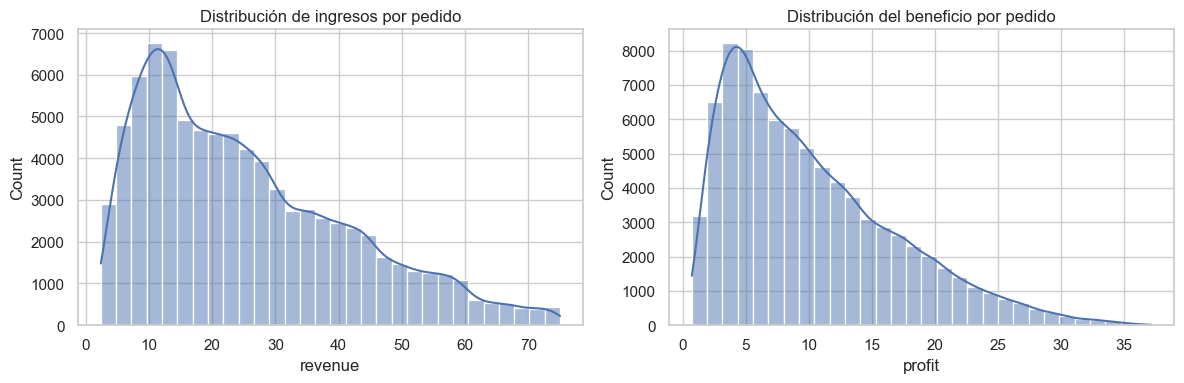

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=eda_df, x="revenue", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribución de ingresos por pedido")

sns.histplot(data=eda_df, x="profit", bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribución del beneficio por pedido")

plt.tight_layout()
guardar_grafico("09_2_distribucion_ingresos_beneficio")
plt.show()

**Interpretación:** las dos distribuciones son asimétricas a la derecha. La mayoría de los pedidos tienen ingresos de entre 5 y 20 (con el pico en torno a 10-15) y beneficios de entre 3 y 8, mientras que una cola de pedidos menos frecuentes llega hasta 75 de ingreso y 37 de beneficio. Esta forma es la esperable al multiplicar un precio y una cantidad que se reparten de forma uniforme: los importes intermedios-bajos son mucho más frecuentes que los máximos, que exigen a la vez precio alto y cantidad alta. Confirma lo observado en 9.1: la mediana describe mejor el pedido típico que la media.

### 9.3. Detección de valores atípicos (outliers)

In [64]:
for columna in ["revenue", "profit", "profit_margin_pct"]:
    q1 = eda_df[columna].quantile(0.25)
    q3 = eda_df[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    atipicos = (eda_df[columna] < limite_inferior) | (eda_df[columna] > limite_superior)
    print(f"{columna}: límites [{limite_inferior:.2f}, {limite_superior:.2f}] -> "
          f"{atipicos.sum()} atípicos ({atipicos.mean() * 100:.2f}%)")

revenue: límites [-23.38, 71.50] -> 608 atípicos (0.73%)
profit: límites [-9.31, 28.29] -> 1252 atípicos (1.51%)
profit_margin_pct: límites [20.12, 59.88] -> 0 atípicos (0.00%)


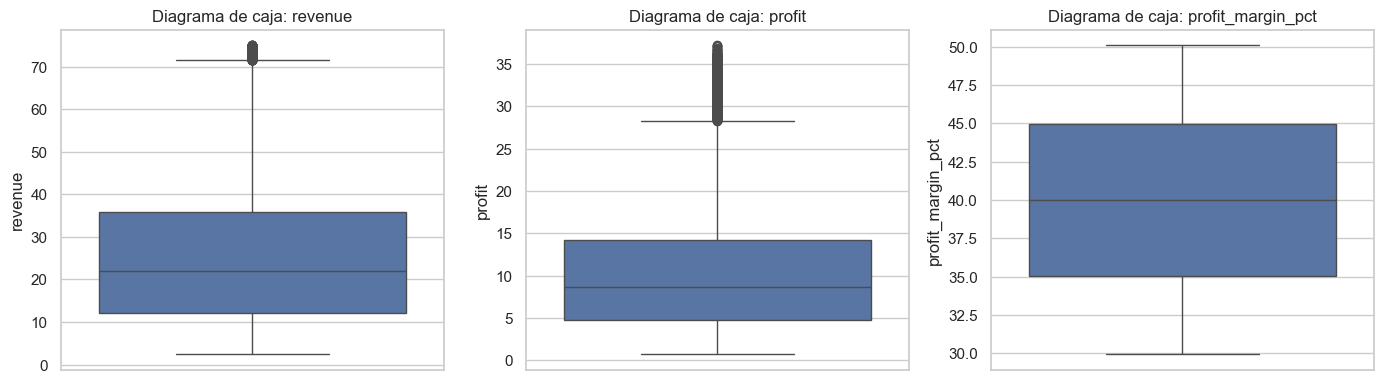

In [79]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, columna in zip(axes, ["revenue", "profit", "profit_margin_pct"]):
    sns.boxplot(y=eda_df[columna], ax=ax)
    ax.set_title(f"Diagrama de caja: {columna}")

plt.tight_layout()
guardar_grafico("09_3_boxplot_valores_atipicos")
plt.show()

- **Ingresos:** 608 pedidos (0,73 %) superan el límite superior de 71,50. Corresponden a pedidos de 5 unidades con un precio alto, cerca del máximo posible (75).
- **Beneficio:** 1.252 pedidos (1,51 %) superan el límite superior de 28,29. Son más que en los ingresos porque la distribución del beneficio es más asimétrica y tiene una cola más larga hacia valores altos.
- **Margen:** no hay valores atípicos; todos los pedidos tienen un margen entre el 30 % y el 50 %.
- **Límite inferior:** en ingresos y beneficio es negativo, por lo que no puede haber atípicos por abajo.

**Decisión:** los valores atípicos se conservan, porque son pedidos válidos (combinaciones reales de precio y cantidad) y no errores. Eliminarlos reduciría artificialmente los ingresos y el beneficio.

### 9.4. Contrastes de comparación de medias

En el análisis descriptivo se observaron pequeñas diferencias entre grupos. Los contrastes permiten comprobar si esas diferencias son reales o si pueden deberse a la variación normal de los datos. Cada subapartado responde a una de las preguntas secundarias del proyecto.

- **Test t de Welch:** compara las medias de dos grupos.
- **ANOVA de un factor:** compara las medias de dos o más grupos.

Se considera que hay diferencia significativa cuando el p-valor es menor que 0,05. Como la muestra es muy grande, también se valora si la diferencia es lo bastante grande como para tener importancia para el negocio.

In [ ]:
resultados_tests = []

def interpretar(p):
    return "Diferencia significativa" if p < 0.05 else "Sin diferencia significativa"

def comparar_grupos(df, columna_grupo, columna_valor):
    """ANOVA de un factor: compara la media de columna_valor entre los grupos de columna_grupo."""
    grupos = [datos[columna_valor] for _, datos in df.groupby(columna_grupo, observed=True)]
    f, p = stats.f_oneway(*grupos)   # el * pasa cada grupo como un argumento separado

    medias = df.groupby(columna_grupo, observed=True)[columna_valor].mean()
    print(f"{columna_valor} según {columna_grupo}")
    display(medias.round(3).to_frame("media"))
    print(f"p-valor: {p:.4f} -> {interpretar(p)}\n")

    resultados_tests.append({
        "contraste": f"{columna_valor} según {columna_grupo}",
        "p_valor": round(p, 4),
        "conclusion": interpretar(p)
    })

#### 9.4.1. Noviembre frente a diciembre

In [69]:
ingresos_nov = ingreso_diario.loc[ingreso_diario["month"] == "November", "revenue"]
ingresos_dic = ingreso_diario.loc[ingreso_diario["month"] == "December", "revenue"]

t, p = stats.ttest_ind(ingresos_dic, ingresos_nov, equal_var=False)

print(f"Ingreso diario medio en noviembre: {ingresos_nov.mean():,.2f}")
print(f"Ingreso diario medio en diciembre: {ingresos_dic.mean():,.2f}")
print(f"Diferencia: {(ingresos_dic.mean() / ingresos_nov.mean() - 1) * 100:.2f}%")
print(f"p-valor: {p:.4f} -> {interpretar(p)}")

resultados_tests.append({
    "contraste": "ingreso diario: diciembre vs noviembre",
    "p_valor": round(p, 4),
    "conclusion": interpretar(p)
})

Ingreso diario medio en noviembre: 34,640.12
Ingreso diario medio en diciembre: 34,850.83
Diferencia: 0.61%
p-valor: 0.3683 -> Sin diferencia significativa


In [70]:
pedidos_nov = eda_df.loc[eda_df["month"] == "November", "revenue"]
pedidos_dic = eda_df.loc[eda_df["month"] == "December", "revenue"]

t, p = stats.ttest_ind(pedidos_dic, pedidos_nov, equal_var=False)

print(f"Ticket medio en noviembre: {pedidos_nov.mean():.3f}")
print(f"Ticket medio en diciembre: {pedidos_dic.mean():.3f}")
print(f"p-valor: {p:.4f} -> {interpretar(p)}")

resultados_tests.append({
    "contraste": "importe por pedido: diciembre vs noviembre",
    "p_valor": round(p, 4),
    "conclusion": interpretar(p)
})

Ticket medio en noviembre: 25.433
Ticket medio en diciembre: 25.567
p-valor: 0.2366 -> Sin diferencia significativa


**Interpretación:** ni el ingreso diario (p = 0,37) ni el importe por pedido (p = 0,24) difieren de forma significativa entre los dos meses. La diferencia del 0,61 % en el ingreso diario y del 0,53 % en el ticket medio es compatible con la variación normal entre días. Por tanto, el aumento de los ingresos totales de diciembre se explica por tener un día más y no por un mejor rendimiento.

#### 9.4.2. Entre semana frente a fin de semana

In [71]:
ingresos_finde = ingreso_diario.loc[ingreso_diario["is_weekend"], "revenue"]
ingresos_semana = ingreso_diario.loc[~ingreso_diario["is_weekend"], "revenue"]

t, p = stats.ttest_ind(ingresos_finde, ingresos_semana, equal_var=False)

print(f"Días de fin de semana: {len(ingresos_finde)} | Días entre semana: {len(ingresos_semana)}")
print(f"Ingreso diario medio en fin de semana: {ingresos_finde.mean():,.2f}")
print(f"Ingreso diario medio entre semana: {ingresos_semana.mean():,.2f}")
print(f"p-valor: {p:.4f} -> {interpretar(p)}")

resultados_tests.append({
    "contraste": "ingreso diario: fin de semana vs entre semana",
    "p_valor": round(p, 4),
    "conclusion": interpretar(p)
})

Días de fin de semana: 18 | Días entre semana: 43
Ingreso diario medio en fin de semana: 34,641.90
Ingreso diario medio entre semana: 34,791.28
p-valor: 0.6186 -> Sin diferencia significativa


**Interpretación:** el ingreso diario medio es prácticamente igual en fin de semana (34.642) y entre semana (34.791), y la diferencia no es significativa (p = 0,62). No hay un patrón de ventas asociado al fin de semana.

#### 9.4.3. Características de los clientes y gasto por pedido

In [72]:
comparar_grupos(eda_df, "gender", "revenue")
comparar_grupos(eda_df, "loyalty_member", "revenue")
comparar_grupos(eda_df, "age_group", "revenue")

revenue según gender


,media
gender,
Female,25.517
Male,25.486


p-valor: 0.7814 -> Sin diferencia significativa

revenue según loyalty_member


,media
loyalty_member,
0,25.661
1,25.343


p-valor: 0.0050 -> Diferencia significativa

revenue según age_group


,media
age_group,
18-29,25.498
30-50,25.509
Más de 50,25.496


p-valor: 0.9948 -> Sin diferencia significativa



**Interpretación:**

- **Género (p = 0,78) y grupo de edad (p = 0,99):** no hay diferencias en el gasto por pedido.
- **Programa de fidelización (p = 0,005):** la diferencia es estadísticamente significativa, pero muy pequeña: los no miembros gastan 25,66 por pedido y los miembros 25,34, una diferencia de 0,32 (1,2 %). Con más de 80.000 pedidos, incluso diferencias mínimas resultan significativas; en la práctica, ser miembro no se asocia a un gasto mayor, sino ligeramente menor.

Como la fecha de alta de los clientes no es fiable, no se puede asegurar que los clientes figuraran como miembros en el momento de la compra.

#### 9.4.4. Tiendas y ubicación

In [73]:
comparar_grupos(eda_df, "store_type", "revenue")
comparar_grupos(eda_df, "country", "revenue")
comparar_grupos(eda_df, "store_type", "profit_margin_pct")
comparar_grupos(eda_df, "country", "profit_margin_pct")

revenue según store_type


,media
store_type,
Airport,25.468
Mall,25.468
Online,25.496
Retail,25.609


p-valor: 0.8297 -> Sin diferencia significativa

revenue según country


,media
country,
Australia,25.548
Canada,25.291
France,25.342
Germany,25.564
UK,25.575
USA,25.741


p-valor: 0.1735 -> Sin diferencia significativa

profit_margin_pct según store_type


,media
store_type,
Airport,40.032
Mall,39.971
Online,40.038
Retail,39.974


p-valor: 0.4817 -> Sin diferencia significativa

profit_margin_pct según country


,media
country,
Australia,39.943
Canada,40.093
France,39.993
Germany,39.992
UK,39.969
USA,40.028


p-valor: 0.2846 -> Sin diferencia significativa



**Interpretación:** ni el importe por pedido ni el margen difieren de forma significativa según el tipo de establecimiento (p = 0,83 y p = 0,48) ni según el país (p = 0,17 y p = 0,28). Esto confirma lo observado en 8.4: las diferencias en los ingresos totales se deben al número de tiendas de cada grupo, no a un mejor rendimiento por pedido.

#### 9.4.5. Descuentos y rentabilidad

In [74]:
comparar_grupos(eda_df, "discount", "profit_margin_pct")
comparar_grupos(eda_df, "discount", "revenue")

# Correlación de Spearman entre el descuento y el margen (no exige distribución normal)
corr_spearman = eda_df["discount"].corr(eda_df["profit_margin_pct"], method="spearman")
print(f"Correlación de Spearman entre descuento y margen: {corr_spearman:.3f}")

profit_margin_pct según discount


,media
discount,
0.00,40.040
0.10,40.024
0.15,39.909
0.20,39.917


p-valor: 0.0616 -> Sin diferencia significativa

revenue según discount


,media
discount,
0.00,26.968
0.10,24.512
0.15,23.039
0.20,21.552


p-valor: 0.0000 -> Diferencia significativa

Correlación de Spearman entre descuento y margen: -0.009


**Interpretación:**

- **Ingreso por pedido (p < 0,001):** disminuye de forma significativa a medida que aumenta el descuento (de 26,97 sin descuento a 21,55 con un 20 %). Es un resultado esperable, porque el descuento reduce directamente el importe pagado.
- **Margen (p = 0,06):** no difiere de forma significativa entre niveles de descuento.
- **Correlación de Spearman (−0,009):** prácticamente nula. Un descuento mayor no se asocia a un margen distinto.

Los descuentos reducen el ingreso por pedido, pero no el margen ni, como se vio en 8.6, el número de unidades compradas.

### 9.5. Asociación entre variables categóricas


In [75]:
tabla = pd.crosstab(eda_df["loyalty_member"], eda_df["has_discount"])
chi2, p, grados_libertad, esperados = stats.chi2_contingency(tabla)

print("Porcentaje de pedidos con y sin descuento según pertenencia al programa")
display((pd.crosstab(eda_df["loyalty_member"], eda_df["has_discount"], normalize="index") * 100).round(2))

print(f"p-valor: {p:.4f} -> {interpretar(p)}")

resultados_tests.append({
    "contraste": "descuento según programa de fidelización (chi-cuadrado)",
    "p_valor": round(p, 4),
    "conclusion": interpretar(p)
})

Porcentaje de pedidos con y sin descuento según pertenencia al programa


has_discount,Con descuento,Sin descuento
loyalty_member,,
0,36.80,63.20
1,37.68,62.32


p-valor: 0.0083 -> Diferencia significativa


### 9.6. Correlaciones y relaciones entre variables

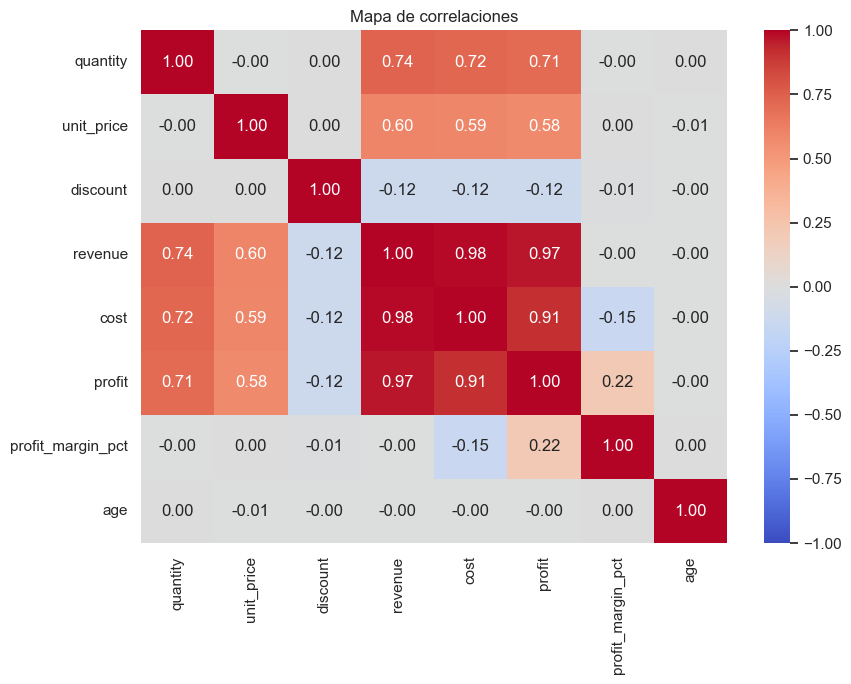

In [76]:
columnas_corr = ["quantity", "unit_price", "discount", "revenue", "cost", "profit", "profit_margin_pct", "age"]
correlaciones = eda_df[columnas_corr].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Mapa de correlaciones")
plt.tight_layout()
guardar_grafico("09_6_mapa_correlaciones")
plt.show()

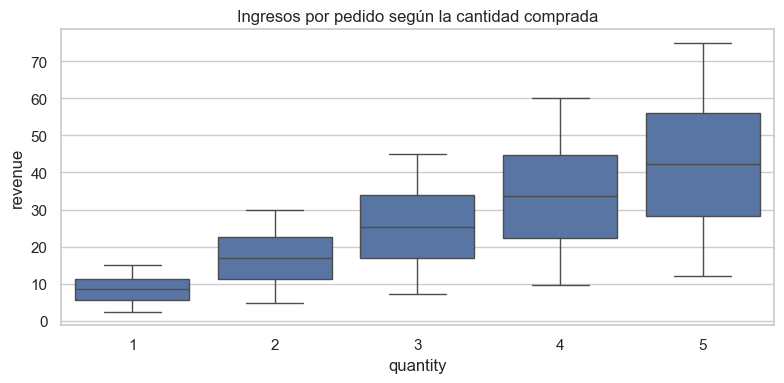

In [77]:
# Relación entre la cantidad comprada y el importe del pedido
plt.figure(figsize=(8, 4))
sns.boxplot(data=eda_df, x="quantity", y="revenue")
plt.title("Ingresos por pedido según la cantidad comprada")
plt.tight_layout()
guardar_grafico("09_6_cantidad_vs_ingresos")
plt.show()

### 9.7. Resumen de los contrastes realizados

In [78]:
tabla_resumen = pd.DataFrame(resultados_tests)
display(tabla_resumen)

,contraste,p_valor,conclusion
0,ingreso diario: diciembre vs noviembre,0.3683,Sin diferencia significativa
1,importe por pedido: diciembre vs noviembre,0.2366,Sin diferencia significativa
2,ingreso diario: fin de semana vs entre semana,0.6186,Sin diferencia significativa
3,revenue según gender,0.7814,Sin diferencia significativa
4,revenue según loyalty_member,0.0050,Diferencia significativa
5,revenue según age_group,0.9948,Sin diferencia significativa
6,revenue según store_type,0.8297,Sin diferencia significativa
7,revenue según country,0.1735,Sin diferencia significativa
8,profit_margin_pct según store_type,0.4817,Sin diferencia significativa
9,profit_margin_pct según country,0.2846,Sin diferencia significativa
